-------------------------------------------------------
f(x) = x⁴ + 2x³ - 7x² + 3
-------------------------------------------------------
Two positive roots found: 
-------------------------------------------------------
Root 1: 1.6180  (full: 1.61803399)
Root 2: 0.7913  (full: 0.79128785)
-------------------------------------------------------
Convergence analysis (x0 = 1.4):
-------------------------------------------------------
Approximate root : 1.6180  (full: 1.61803399)
Total iterations : 5
Error progression:
Iteration 1: e_1 = 0.4434 (4.4337e-01)
Iteration 2: e_2 = 0.1674 (1.6744e-01)
Iteration 3: e_3 = 0.0526 (5.2566e-02)
Iteration 4: e_4 = 0.0053 (5.2714e-03)
Iteration 5: e_5 = 0.0001 (5.1418e-05)
-------------------------------------------------------


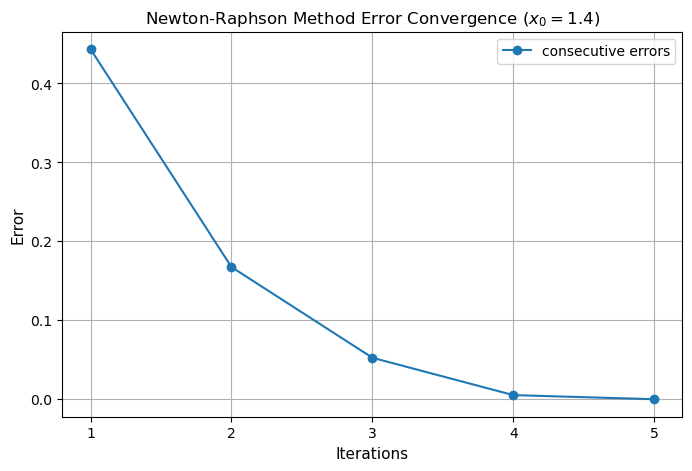

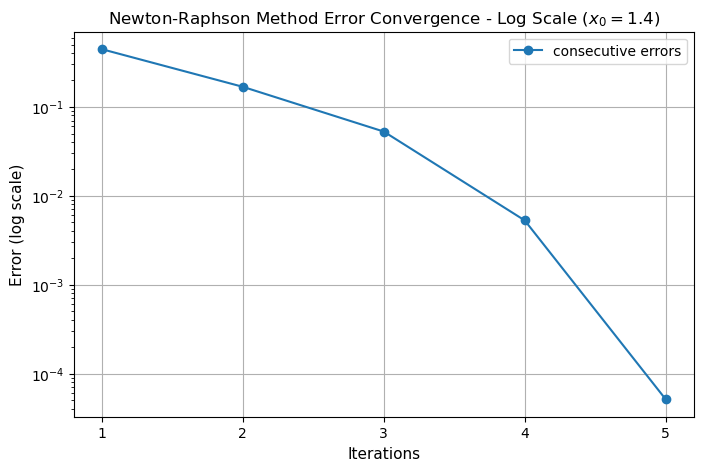

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#declaration of function f(x)
def f(x):
    return x**4 + 2*x**3 - 7*x**2 + 3

#declaration of the derivative of f: df(x)
def df(x):
    return 4*x**3 + 6*x**2 - 14*x

#1. Newton-Raphson method implementation
#Inputs: initial approximation (x0), error tolerance (tol), maximum iterations (maxit)
#Outputs: approximate root (x_next), list of consecutive errors (errors)
def Newton_Raphson( x0, tol, maxit ):
    errors = []
    for i in range(maxit):
        x_next = x0 - f(x0) / df(x0)
        errors.append(np.abs(x_next - x0))
        #convergence stopping criterion
        if np.abs(x_next - x0) < tol:
            break
        x0 = x_next
    return x_next, errors

#2. Calculating the two distinct positive roots starting from x0 = i * 0.1
x_i = []
i = 0
tol = 1e-4
while True:
    x0 = i * 0.1
    if df(x0) == 0:   #We avoid division by zero if f'(x0) == 0 (ZeroDivisionError)
        i += 1
        continue
        
    sol, err = Newton_Raphson( x0 , tol, 15 )
    #We store the first discovered root
    if len(x_i) == 0:
        x_i.append(sol)
        i += 1
    #We check if the root matches the first one within the specified tolerance
    elif np.abs(x_i[0] - sol) < tol:
        i += 1
        continue
    #Second distinct root found; loop termination
    else:
        x_i.append(sol)
        break
        
#Output printing rounded to 4 decimal digits
print("-" * 55)
print("f(x) = x⁴ + 2x³ - 7x² + 3")
print("-" * 55)
print("Two positive roots found: ")
print("-" * 55)
print(f"Root 1: {x_i[0]:.4f}  (full: {x_i[0]:.8f})")
print(f"Root 2: {x_i[1]:.4f}  (full: {x_i[1]:.8f})")
print("-" * 55)

#3. Convergence study and error plot for x0 = 1.4
n_sol, n_errors = Newton_Raphson( 1.4 , 1e-4, 10 )
print("Convergence analysis (x0 = 1.4):")
print("-" * 55)
print(f"Approximate root : {n_sol:.4f}  (full: {n_sol:.8f})")
print(f"Total iterations : {len(n_errors)}")
print("Error progression:")
for index, error_value in enumerate(n_errors, start=1):
    print(f"Iteration {index}: e_{index} = {error_value:.4f} ({error_value:.4e})")
print("-" * 55)

#We generate the error convergence plot
plt.figure(figsize = (8, 5))
iterations = range(1, len(n_errors) + 1)
plt.plot(iterations, n_errors, marker='o', label='consecutive errors')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Error', fontsize=11)
plt.title('Newton-Raphson Method Error Convergence ($x_0 = 1.4$)', fontsize=12)
plt.xticks(iterations) #We display integer iteration ticks on the x-axis
plt.grid()
plt.legend()
plt.show()

#We generate the error convergence plot (Log Scale)
plt.figure(figsize = (8, 5))
iterations = range(1, len(n_errors) + 1)
plt.plot(iterations, n_errors, marker='o', label='consecutive errors')
plt.yscale('log')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Error (log scale)', fontsize=11)
plt.title('Newton-Raphson Method Error Convergence - Log Scale ($x_0 = 1.4$)', fontsize=12)
plt.xticks(iterations) #We display integer iteration ticks on the x-axis
plt.grid()
plt.legend()
plt.show()